![Python Banner](../../Image/05_01_tree_based_models.png)


# 1.8 Boosted Multi-Arm Causal Model



## Overview

A **Boosted Multi-Arm Causal Model** estimates heterogeneous treatment effects (HTE) in settings with more than two treatment options — for example, a placebo arm alongside two or more active interventions. Rather than fitting a single causal model across all arms simultaneously, it adopts a **T-learner strategy**: one outcome model per arm, each capturing the arm-specific relationship between covariates and outcomes. Treatment effects are then recovered as contrasts between arm predictions, relative to a chosen baseline.

The "boosted" label refers to the learner: each contrast is a **boosted X-learner** (`CXGBoost`). That brings XGBoost's tabular strengths — nonlinear interactions, robustness to irrelevant features, and stable fits on moderate samples — to each arm contrast.

This approach trades off some efficiency (arm models share no parameters) for simplicity and flexibility: it makes no assumptions about how treatment effects relate across arms, and each arm model can be tuned independently.

### When to Use It

The Boosted Multi-Arm Causal Model is appropriate when:

-   There are $K \geq 3$ treatment conditions (including control/placebo), and binary causal forest methods do not apply directly.
-   The relationship between covariates and outcomes is likely nonlinear or involves interactions that regression-based methods would miss.
-   The primary goal is **individual-level treatment effect estimation** — identifying which arm benefits which subgroup — rather than population-average inference.
-   Observational data requires covariate adjustment, and a binary treatment model does not match the design.

Typical applications include clinical trials comparing multiple drug regimens against placebo, policy evaluations with several intervention variants, and marketing experiments with multiple campaign conditions.

### Key Concepts

**T-learner.** The T-learner (or "treatment-specific learner") fits a separate outcome model for each arm $k$:

$$\hat{\mu}_k(x) \approx E[Y \mid X = x,\, W = k], \qquad k = 0, 1, \ldots, K-1$$

where arm $k = b$ (typically $k = 0$, placebo or control) serves as the **baseline**. Each model is trained only on units assigned to arm $k$, so the models are entirely independent of one another.

**Treatment contrasts.** The conditional average treatment effect (CATE) for arm $k$ relative to baseline $b$ is:

$$\tau_{k \leftarrow b}(x) = \hat{\mu}_k(x) - \hat{\mu}_b(x)$$

For $K$ arms, this yields $K - 1$ contrast surfaces over the covariate space. For example, with arms $\{$placebo, drug A, drug B$\}$, the model returns $\hat{\tau}_{A \leftarrow \text{placebo}}(x)$ and $\hat{\tau}_{B \leftarrow \text{placebo}}(x)$ for each individual.

**Pairwise contrasts.** Any two non-baseline arms can also be compared directly:

$$\tau_{k \leftarrow j}(x) = \hat{\mu}_k(x) - \hat{\mu}_j(x)$$

This is straightforward since all $\hat{\mu}_k$ are defined over the full covariate space.

**Propensity scores.** A multiclass propensity model estimates $\hat{e}_k(x) = P(W = k \mid X = x)$ for all arms jointly, typically using a probability forest or multinomial model. These propensity scores are **not** incorporated into the outcome model training (the approach is not doubly robust), but serve three diagnostic purposes: detecting covariate imbalance across arms, flagging low-overlap regions where counterfactual predictions are unreliable, and enabling inverse probability weighting (IPW) for population-level ATE estimation if needed.

**Identification assumptions.** Like all observational causal methods, the T-learner requires:

-   **Consistency** — the observed outcome for a unit assigned to arm $k$ equals its potential outcome $Y(k)$.
-   **Ignorability** — conditional on $X$, treatment assignment is independent of potential outcomes: $W \perp (Y(0), \ldots, Y(K-1)) \mid X$. There must be no unmeasured confounders.
-   **Overlap** — every unit has a non-zero probability of receiving any arm: $P(W = k \mid X = x) > 0$ for all $k$ and all $x$ in the support.

### Known Limitations

**T-learner bias in small arms.** When one arm has few observations, its outcome model is poorly estimated, which degrades the contrast estimates for that arm disproportionately. S-learner or X-learner variants can partially mitigate this by sharing information across arms.

**No regularization toward a common effect.** Unlike the Multi-Arm/Multi-Outcome Causal Forest (which uses a joint splitting criterion), T-learner arm models are fully independent. If treatment effects are genuinely similar across arms, a joint model would be more efficient.

**Not doubly robust.** Propensity scores are estimated but not used in the outcome model training. Misspecification of $\hat{\mu}_k$ is not corrected by a well-estimated propensity model.

**Extrapolation risk.** Each $\hat{\mu}_k$ must produce predictions for all units regardless of arm assignment — including covariate regions where that arm had few or no training observations. Low-propensity regions should be interpreted cautiously.

### Pipeline: Five Steps

![Boosted multi-arm causal model](<../../Image/Boosted Multi-Arm Causal Model.png>)

A few things worth emphasizing from the pipeline:

**Step 2 extrapolation is the central challenge.** Each arm model is trained on only the units assigned to that arm, but must predict $\hat{\mu}_k(x)$ for *every* unit in the dataset — including those from other arms. In regions of covariate space where arm $k$ is rare (low propensity), the model is extrapolating from very little data. The propensity scores in step 4 directly diagnose this risk: wherever $\hat{e}_k(x)$ is near zero, the corresponding $\hat{\mu}_k(x)$ estimates should be treated with caution.

**Step 3's "best arm" output** is operationally the most useful in personalized treatment settings. For each individual, the model returns $\text{argmax}_k\, \hat{\tau}_{k \leftarrow b}(x)$, identifying which arm delivers the largest estimated benefit. This is the basis for **individualized treatment rules (ITRs)** — policies that assign different arms to different subgroups based on predicted effect heterogeneity. That said, uncertainty around CATE estimates should be factored in before acting on these assignments; small margin differences between arms may not be reliable.

**Step 4 propensity scores serve three distinct roles** that are worth keeping separate: (1) *diagnostics* — visualizing covariate overlap across arms to identify extrapolation risk; (2) *ATE correction* — IPW-adjusted averages account for non-random arm assignment in observational data; and (3) *sensitivity analysis* — comparing naive and propensity-weighted ATEs reveals how sensitive conclusions are to the observational design.



## Implementation in Python

`MultiArmCausalBoost` in PyCausalML fits one boosted contrast model per non-baseline arm. The implementation is designed for flexibility and interpretability, with the following features:

-   **Outcome models**: one `CXGBoost` model per contrast against the baseline.
-   **Propensity model**: a logistic regression inside each contrast model, used to combine the arm-specific effect estimates.
-   **Prediction output**: `predict(X)` returns one contrast column per non-baseline arm.


## Setup

This notebook fits **`MultiArmCausalBoost`** from **[PyCausalML](https://github.com/zia207/PyCausalML)** (`pycausalml.tree_based_models`).

`fit(X, treatment, y)` returns the fitted estimator. `predict` returns a NumPy array of conditional average treatment effects. A fitted model also exposes `explain` and `plot_shap`.

Install the package from this repository, with the plotting and boosting extras.

The three-arm example is built with `make_patient_multiarm` from `Data/patients.csv`, the same design as the multi-arm causal forest tutorial. One boosted model is fit for each outcome. Arm labels are coded `placebo=0`, `A=1`, `B=2`, and the baseline arm is `0`.


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot,boost,shap]", "statsmodels",
])
print("PyCausalML ready.")


PyCausalML ready.


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from pycausalml import (
    MultiArmCausalBoost,
    explain_cate,
)

import sys
from pathlib import Path

def _add_methods_path():
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        for rel in (
            Path("causal_tree_methods.py"),
            Path("Tutorials") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
            Path("Notebook") / "05_01_Tree_Based_Models" / "causal_tree_methods.py",
        ):
            path = cand / rel
            if path.is_file():
                sys.path.insert(0, str(path.parent))
                return
    raise FileNotFoundError("causal_tree_methods.py was not found")

_add_methods_path()
from causal_tree_methods import (
    make_patient_multiarm,
)

def find_repo_root(start=None) -> Path:
    here = Path(start or Path.cwd()).resolve()
    for cand in [here, *here.parents]:
        if (cand / "Data").is_dir() and (cand / "Image").is_dir():
            return cand
    raise FileNotFoundError("Could not find a folder containing Data/ and Image/.")

def data_path(filename: str) -> Path:
    return find_repo_root() / "Data" / filename

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
print("Imported PyCausalML")


Imported PyCausalML


### Prepare the patient dataset

The example is built from `Data/patients.csv`: real age, comorbidity, baseline risk, and sex, a simulated three-arm treatment (`placebo`, `A`, `B`), observed log length of stay, and a simulated binary clinical response that improves under A and more so under B.

`make_patient_multiarm` builds that design from `Data/patients.csv`:

- Draws a three-level `treatment` (`placebo`, `A`, `B`) with probabilities 40%, 30%, and 30%.
- Keeps observed log length of stay (`log_los`) as the first outcome. Treatment is randomized, so its effect on length of stay is null.
- Simulates a binary clinical `response` that is higher under arm A and higher still under arm B.


In [3]:
design = make_patient_multiarm(n=2000, random_state=123)
frame = design["frame"]
X, Y, W = design["X"], design["Y"], design["W"]
feature_names = design["feature_names"]
outcome_names = design["outcome_names"]
rng = np.random.default_rng(123)
n = len(W)
train_idx = rng.choice(n, size=int(0.8 * n), replace=False)
test_idx = np.setdiff1d(np.arange(n), train_idx)
X_train, X_test = X[train_idx], X[test_idx]
W_train, W_test = W[train_idx], W[test_idx]
Y_train, Y_test = Y[train_idx], Y[test_idx]
print(pd.Series(W_train).value_counts())
print("outcomes", outcome_names)
print("covariates", feature_names)


placebo    641
A          498
B          461
Name: count, dtype: int64
outcomes ['log_los', 'response']
covariates ['age_z', 'comorbidity_z', 'baseline_risk_z', 'gender_male']


### Train `MultiArmCausalBoost` on `log_los` and `response`

`MultiArmCausalBoost` fits one boosted contrast per non-baseline arm. This notebook fits a separate model for each outcome, `log_los` and `response`.

- one `CXGBoost` contrast against placebo for arm A, and one for arm B
- a logistic propensity model inside each contrast, used only to combine that contrast's effect estimates

Key choices you control:

-   **baseline**: the reference arm for contrasts (placebo, coded as 0)
-   **learner**: `"xgb"` for XGBoost or `"gbr"` for gradient boosting
-   **n_estimators**: boosting rounds (kept moderate for tutorial runtime)


In [4]:
ARM = {"placebo": 0, "A": 1, "B": 2}
CONTRAST = {1: "A - placebo", 2: "B - placebo"}
W_code = np.array([ARM[str(a)] for a in W_train])
model_los = MultiArmCausalBoost(baseline=0, n_estimators=40, learner="xgb", random_state=1)
model_resp = MultiArmCausalBoost(baseline=0, n_estimators=40, learner="xgb", random_state=2)
model_los.fit(X_train, W_code, Y_train[:, 0], feature_names=feature_names)
model_resp.fit(X_train, W_code, Y_train[:, 1], feature_names=feature_names)
print("contrasts", [CONTRAST[int(arm)] for arm in model_los.arms_])
print("mean training CATE, log_los", np.round(model_los.predict(X_train).mean(axis=0), 3))
print("mean training CATE, response", np.round(model_resp.predict(X_train).mean(axis=0), 3))


contrasts ['A - placebo', 'B - placebo']
mean training CATE, log_los [0.046 0.1  ]
mean training CATE, response [0.107 0.214]


## Predict contrasts on the test set

`predict(X)` returns a numeric array with one column per non-baseline arm, in the order stored on `arms_`. Each column is the conditional contrast against placebo. Propensity scores stay on each contrast model's `propensity_` attribute; they are not part of the prediction array.

In [5]:
tau_hat_log_los = np.asarray(model_los.predict(X_test))
tau_hat_response = np.asarray(model_resp.predict(X_test))
columns = [CONTRAST[int(arm)] for arm in model_los.arms_]
print("log length of stay")
print(pd.DataFrame(tau_hat_log_los, columns=columns).head())
print("clinical response")
print(pd.DataFrame(tau_hat_response, columns=columns).head())


log length of stay
   A - placebo  B - placebo
0     0.035568     0.124001
1     0.005817    -0.013249
2     0.037126     0.008549
3    -0.027519     0.151351
4    -0.047768     0.152438
clinical response
   A - placebo  B - placebo
0     0.070772     0.335861
1     0.055840     0.125987
2     0.160307     0.266076
3     0.077687     0.174736
4     0.114828     0.137205


## Average predicted contrasts on the training set

These averages are the mean of `predict(X)` on the training rows. They are model-implied contrasts against placebo, not a doubly robust score. Treatment in this example is randomized, so the mean contrast is a direct summary of the fitted surface.

In [6]:
print("Mean training contrast, log_los")
print(pd.Series(model_los.predict(X_train).mean(axis=0), index=columns).round(3))
print("Mean training contrast, response")
print(pd.Series(model_resp.predict(X_train).mean(axis=0), index=columns).round(3))


Mean training contrast, log_los
A - placebo    0.046
B - placebo    0.100
dtype: float64
Mean training contrast, response
A - placebo    0.107
B - placebo    0.214
dtype: float64


### Summarize average (model-implied) contrasts on the test set

The test-set table is the average of the predicted individual contrasts for `log_los` and `response`.

In [7]:
avg_tau = pd.DataFrame(
    {
        "log_los": tau_hat_log_los.mean(axis=0),
        "response": tau_hat_response.mean(axis=0),
    },
    index=columns,
)
print(avg_tau.round(3))


             log_los  response
A - placebo    0.045     0.104
B - placebo    0.103     0.219


### Visualize heterogeneity in a contrast

As a simple check, plot a contrast against a key covariate.

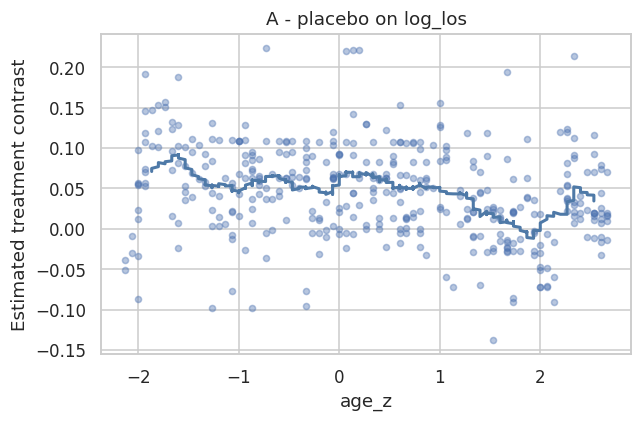

In [8]:
plot_df = pd.DataFrame({
    "age_z": X_test[:, 0],
    "tau": tau_hat_log_los[:, 0],
})
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(plot_df["age_z"], plot_df["tau"], alpha=0.4, s=16)
order = np.argsort(plot_df["age_z"].to_numpy())
window = 40
smooth = np.convolve(plot_df["tau"].to_numpy()[order], np.ones(window) / window, mode="valid")
ax.plot(
    plot_df["age_z"].to_numpy()[order][window // 2: window // 2 + len(smooth)],
    smooth,
    color="#4E79A7",
    lw=2,
)
ax.set_xlabel("age_z")
ax.set_ylabel("Estimated treatment contrast")
ax.set_title(f"{columns[0]} on log_los")
fig.tight_layout()
plt.show()


## Variable importance: `log_los` and `response`

`feature_importance()` averages importance across the contrast models. The plots show log length of stay and clinical response separately.


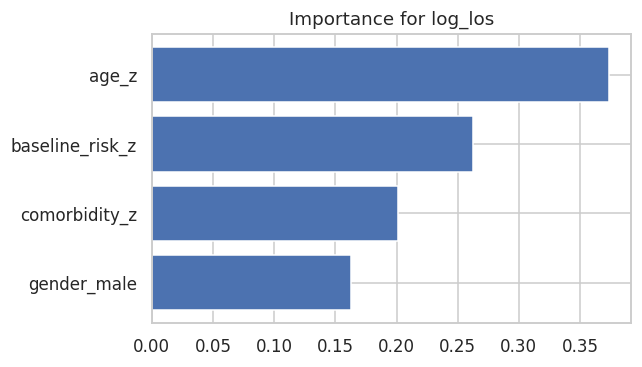

In [9]:
imp = model_los.feature_importance()
order = np.argsort(imp)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(np.array(feature_names)[order], imp[order], color="#4C72B0")
ax.set_title("Importance for log_los")
fig.tight_layout()
plt.show()


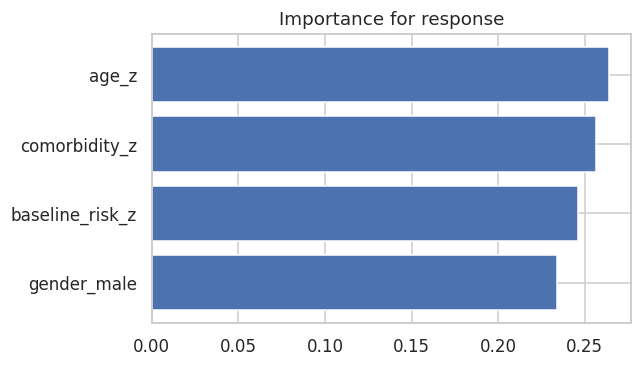

In [10]:
imp = model_resp.feature_importance()
order = np.argsort(imp)
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.barh(np.array(feature_names)[order], imp[order], color="#4C72B0")
ax.set_title("Importance for response")
fig.tight_layout()
plt.show()


### Contrast models

`models_` holds one fitted `CXGBoost` per non-baseline arm. The first entry is the A-versus-placebo contrast.

In [11]:
print(model_los.models_[0])


### SHAP values for the predicted contrasts

These plots explain the predicted log-length-of-stay contrasts against placebo. `explain_cate` uses a subsample of the test rows so the permutation explainer stays small.


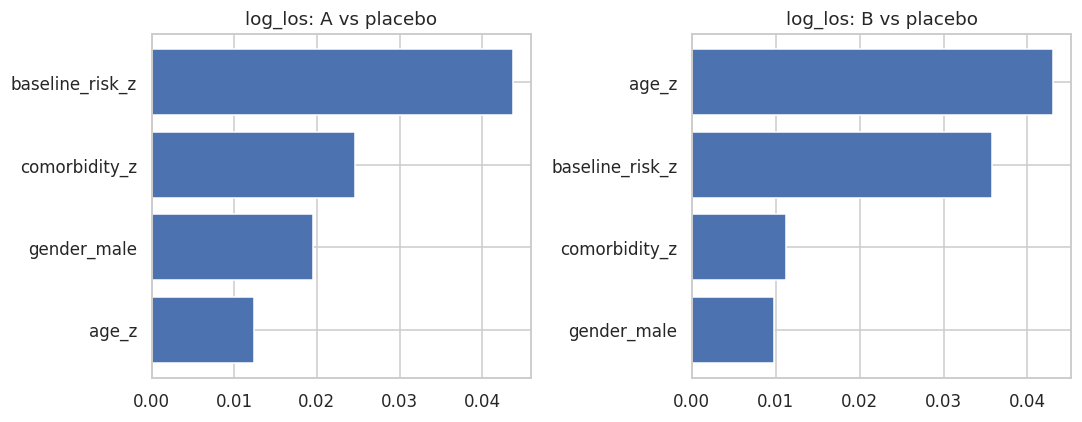

In [12]:
class _Contrast:
    def __init__(self, model, column):
        self.model = model
        self.column = column
        self.feature_names_ = feature_names

    def predict(self, new_x):
        return np.asarray(self.model.predict(new_x))[:, self.column]

sv_A = explain_cate(_Contrast(model_los, 0), X_test, feature_names=feature_names, max_samples=30, random_state=1)
sv_B = explain_cate(_Contrast(model_los, 1), X_test, feature_names=feature_names, max_samples=30, random_state=1)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, sv, title in (
    (axes[0], sv_A, "log_los: A vs placebo"),
    (axes[1], sv_B, "log_los: B vs placebo"),
):
    order = np.argsort(sv.importance())
    ax.barh(np.array(feature_names)[order], sv.importance()[order], color="#4C72B0")
    ax.set_title(title)
fig.tight_layout()
plt.show()


## Save and load a fitted model

The fitted object can be written and read with `pickle`.

In [13]:
import pickle

tmp_path = Path("multi_arm_causal_boost_demo.pkl")
with tmp_path.open("wb") as handle:
    pickle.dump(model_los, handle)
with tmp_path.open("rb") as handle:
    model2 = pickle.load(handle)
print(np.round(model2.predict(X_test[:5]), 3))
tmp_path.unlink()


[[ 0.036  0.124]
 [ 0.006 -0.013]
 [ 0.037  0.009]
 [-0.028  0.151]
 [-0.048  0.152]]


## Notes and limitations

- Each contrast is a boosted X-learner against placebo, fit only on the baseline arm and that arm.
- Propensity scores are used inside each contrast. The averages above are means of predicted contrasts, not a doubly robust score.
- Each arm needs enough rows, because that arm's outcome model is trained only on units assigned to it.
- The two outcomes are fit separately. The models do not share an outcome-correlation structure.
- SHAP explains the predicted contrast. That is the structural effect only when the identification assumptions hold.

## Summary

This tutorial fit `MultiArmCausalBoost` on the three-arm design built from `Data/patients.csv`:

- one model for `log_los` and one for `response`
- contrasts of arms A and B against placebo
- average predicted contrasts, covariate importance, and SHAP explanations of those contrasts

## Resources

1.  Künzel, S. R., Sekhon, J. S., Bickel, P. J., & Yu, B. (2019). Metalearners for estimating heterogeneous treatment effects using machine learning. PNAS.
2.  [XGBoost documentation](https://xgboost.readthedocs.io/) for boosted trees and model interpretation.
